In [1]:
print("Hello! This is my first Automotive Data Analysis Project.")


Hello! This is my first Automotive Data Analysis Project.


In [2]:
# My first Python calculations

a = 10
b = 20

print("Addition:", a + b)
print("Subtraction:", b - a)
print("Multiplication:", a * b)
print("Division:", b / a)

Addition: 30
Subtraction: 10
Multiplication: 200
Division: 2.0


In [3]:
!pip -q install ucimlrepo

In [4]:
import pandas as pd
from ucimlrepo import fetch_ucirepo

# Download the Auto MPG dataset
auto_mpg = fetch_ucirepo(id=9)

# Separate the vehicle details and MPG values
X = auto_mpg.data.features
y = auto_mpg.data.targets

# Combine everything into one table
df = pd.concat([X, y], axis=1)

print("Automotive dataset loaded successfully!")

Automotive dataset loaded successfully!


In [5]:
df.head()

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg
0,307.0,8,130.0,3504,12.0,70,1,18.0
1,350.0,8,165.0,3693,11.5,70,1,15.0
2,318.0,8,150.0,3436,11.0,70,1,18.0
3,304.0,8,150.0,3433,12.0,70,1,16.0
4,302.0,8,140.0,3449,10.5,70,1,17.0


In [6]:
print("Number of rows and columns:", df.shape)

Number of rows and columns: (398, 8)


In [7]:
# Save our automotive dataset

df.to_csv("auto_mpg_dataset.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [8]:
from google.colab import files

files.download("auto_mpg_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
# STEP 1: Display all column names

print("Columns available in our dataset:")
print(df.columns.tolist())

Columns available in our dataset:
['displacement', 'cylinders', 'horsepower', 'weight', 'acceleration', 'model_year', 'origin', 'mpg']


In [10]:
# STEP 2: Display the first 10 vehicle records

df.head(10)

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg
0,307.0,8,130.0,3504,12.0,70,1,18.0
1,350.0,8,165.0,3693,11.5,70,1,15.0
2,318.0,8,150.0,3436,11.0,70,1,18.0
3,304.0,8,150.0,3433,12.0,70,1,16.0
4,302.0,8,140.0,3449,10.5,70,1,17.0
5,429.0,8,198.0,4341,10.0,70,1,15.0
6,454.0,8,220.0,4354,9.0,70,1,14.0
7,440.0,8,215.0,4312,8.5,70,1,14.0
8,455.0,8,225.0,4425,10.0,70,1,14.0
9,390.0,8,190.0,3850,8.5,70,1,15.0


In [11]:
# STEP 3: Check dataset information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   displacement  398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   horsepower    392 non-null    float64
 3   weight        398 non-null    int64  
 4   acceleration  398 non-null    float64
 5   model_year    398 non-null    int64  
 6   origin        398 non-null    int64  
 7   mpg           398 non-null    float64
dtypes: float64(4), int64(4)
memory usage: 25.0 KB


In [12]:
# STEP 4: Identify missing values

print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
displacement    0
cylinders       0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
mpg             0
dtype: int64


In [13]:
# STEP 5: Generate statistical summary

df.describe()

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg
count,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000,398.000000,398.000000
mean,193.425879,5.454774,104.469388,2970.424623,15.568090,76.010050,1.572864,23.514573
std,104.269838,1.701004,38.491160,846.841774,2.757689,3.697627,0.802055,7.815984
min,68.000000,3.000000,46.000000,1613.000000,8.000000,70.000000,1.000000,9.000000
25%,104.250000,4.000000,75.000000,2223.750000,13.825000,73.000000,1.000000,17.500000
50%,148.500000,4.000000,93.500000,2803.500000,15.500000,76.000000,1.000000,23.000000
75%,262.000000,8.000000,126.000000,3608.000000,17.175000,79.000000,2.000000,29.000000
max,455.000000,8.000000,230.000000,5140.000000,24.800000,82.000000,3.000000,46.600000


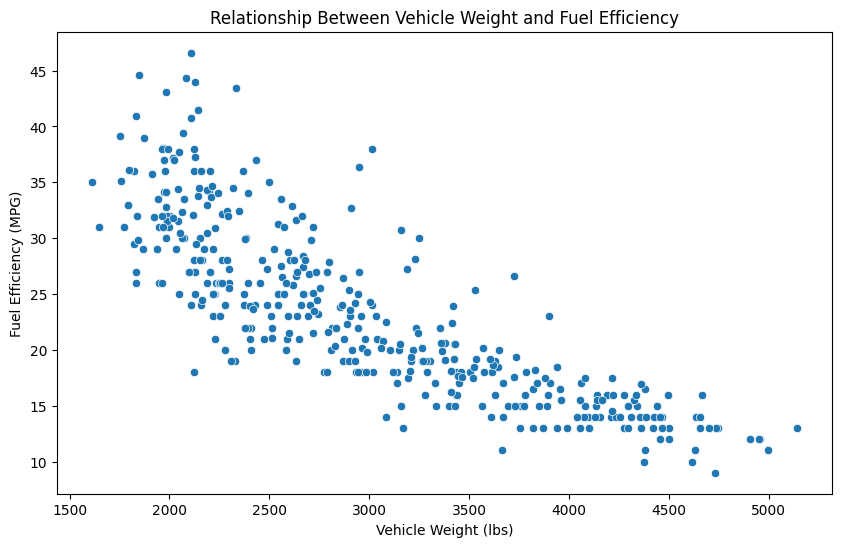

In [14]:
# STEP 1: Import visualisation libraries

import matplotlib.pyplot as plt
import seaborn as sns

# STEP 2: Create a scatter plot

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='weight',
    y='mpg'
)

# STEP 3: Add graph labels and title

plt.title("Relationship Between Vehicle Weight and Fuel Efficiency")

plt.xlabel("Vehicle Weight (lbs)")
plt.ylabel("Fuel Efficiency (MPG)")

# STEP 4: Display the graph

plt.show()

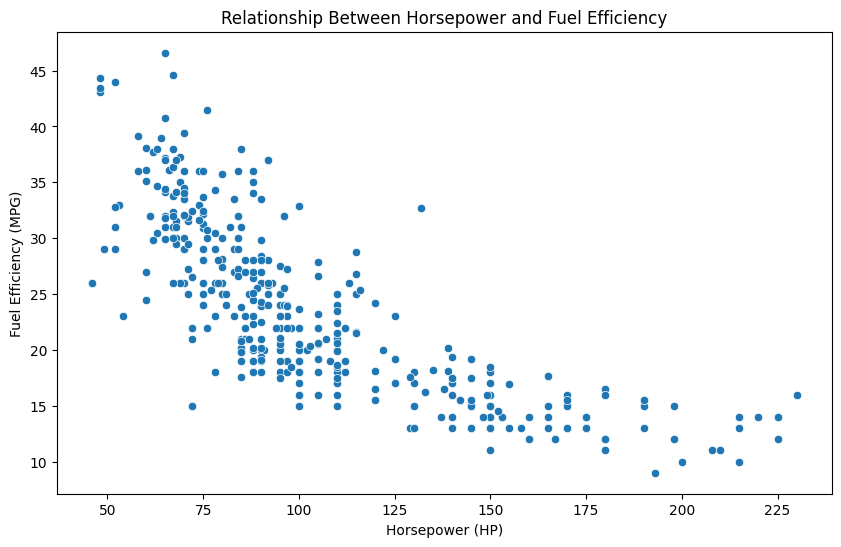

In [15]:
# Relationship between horsepower and fuel efficiency

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='horsepower',
    y='mpg'
)

plt.title("Relationship Between Horsepower and Fuel Efficiency")

plt.xlabel("Horsepower (HP)")
plt.ylabel("Fuel Efficiency (MPG)")

plt.show()

In [16]:
# STEP 1: Calculate correlation

correlation = df[['weight', 'horsepower', 'mpg']].corr()

print(correlation)

              weight  horsepower       mpg
weight      1.000000    0.864538 -0.831741
horsepower  0.864538    1.000000 -0.778427
mpg        -0.831741   -0.778427  1.000000


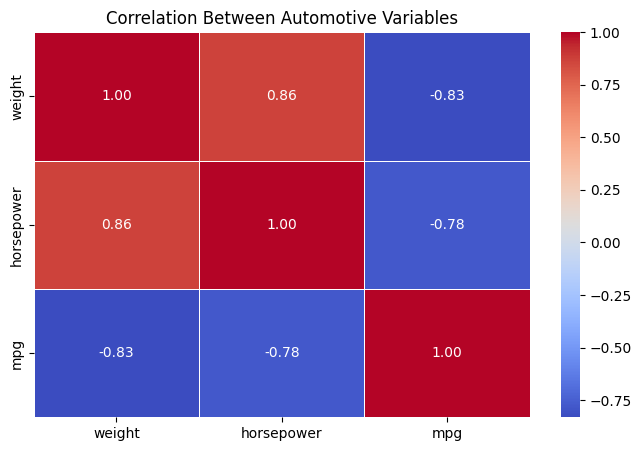

In [17]:
# STEP 2: Visualise correlation using a heatmap

plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Between Automotive Variables")

plt.show()

In [18]:
# STEP 1: Check missing values

print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
displacement    0
cylinders       0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
mpg             0
dtype: int64


In [19]:
# STEP 2: Display records with missing horsepower

missing_hp = df[df['horsepower'].isnull()]

print("Records with missing horsepower:")
display(missing_hp)

print("Total missing records:", len(missing_hp))

Records with missing horsepower:


,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg
32,98.0,4,NaN,2046,19.0,71,1,25.0
126,200.0,6,NaN,2875,17.0,74,1,21.0
330,85.0,4,NaN,1835,17.3,80,2,40.9
336,140.0,4,NaN,2905,14.3,80,1,23.6
354,100.0,4,NaN,2320,15.8,81,2,34.5
374,151.0,4,NaN,3035,20.5,82,1,23.0


Total missing records: 6


In [20]:
# STEP 1: Create a separate copy of the dataset

df_clean = df.copy()

print("Original dataset:", df.shape)
print("Working dataset:", df_clean.shape)

Original dataset: (398, 8)
Working dataset: (398, 8)


In [21]:
# STEP 2: Calculate median horsepower

median_hp = df_clean['horsepower'].median()

print("Median horsepower:", median_hp)

Median horsepower: 93.5


In [22]:
# STEP 3: Replace missing horsepower values

df_clean['horsepower'] = df_clean['horsepower'].fillna(median_hp)

print("Missing horsepower values after cleaning:")
print(df_clean['horsepower'].isnull().sum())

Missing horsepower values after cleaning:
0


In [23]:
# STEP 4: Verify the cleaned dataset

print("Dataset dimensions:", df_clean.shape)

print("\nMissing values in each column:")
print(df_clean.isnull().sum())

Dataset dimensions: (398, 8)

Missing values in each column:
displacement    0
cylinders       0
horsepower      0
weight          0
acceleration    0
model_year      0
origin          0
mpg             0
dtype: int64


In [24]:
# STEP 5: Export the cleaned dataset

df_clean.to_csv("auto_mpg_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [25]:
from google.colab import files

files.download("auto_mpg_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:
# STEP 1: Import machine learning libraries

import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

print("Machine learning libraries imported successfully!")

Machine learning libraries imported successfully!


In [27]:
# STEP 2: Define input and target variables

X = df_clean[
    [
        'cylinders',
        'displacement',
        'horsepower',
        'weight',
        'acceleration',
        'model_year',
        'origin'
    ]
]

y = df_clean['mpg']

print("Input variables:", X.shape)
print("Target variable:", y.shape)

Input variables: (398, 7)
Target variable: (398,)


In [28]:
# STEP 3: Split the dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 318
Testing records: 80


In [29]:
# STEP 4: Create and train the model

model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression Model trained successfully!")

Linear Regression Model trained successfully!


In [30]:
# STEP 5: Generate predictions

y_pred = model.predict(X_test)

print("First 10 actual MPG values:")
print(y_test.head(10).values)

print("\nFirst 10 predicted MPG values:")
print(y_pred[:10])

First 10 actual MPG values:
[33. 28. 19. 13. 14. 27. 24. 13. 17. 21.]

First 10 predicted MPG values:
[32.88140046 29.55780381 21.36955005 16.79734409 12.4982001  27.20579297
 27.90034172  9.77551057 16.88434148 22.03432001]


In [31]:
# STEP 6: Evaluate model performance

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Model Performance")
print("-------------------------")

print("Mean Absolute Error:", round(mae, 2))
print("Mean Squared Error:", round(mse, 2))
print("Root Mean Squared Error:", round(rmse, 2))
print("R2 Score:", round(r2, 3))

Model Performance
-------------------------
Mean Absolute Error: 2.26
Mean Squared Error: 8.2
Root Mean Squared Error: 2.86
R2 Score: 0.848


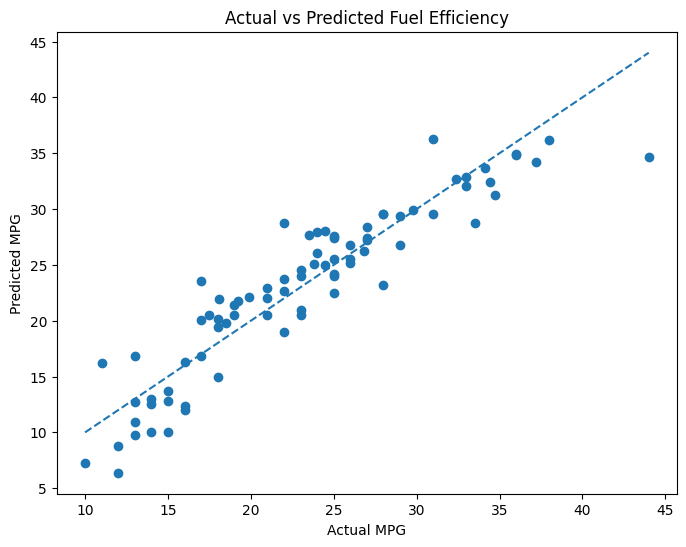

In [32]:
# STEP 7: Actual vs Predicted MPG

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred)

# Add a reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.title("Actual vs Predicted Fuel Efficiency")

plt.xlabel("Actual MPG")
plt.ylabel("Predicted MPG")

plt.show()

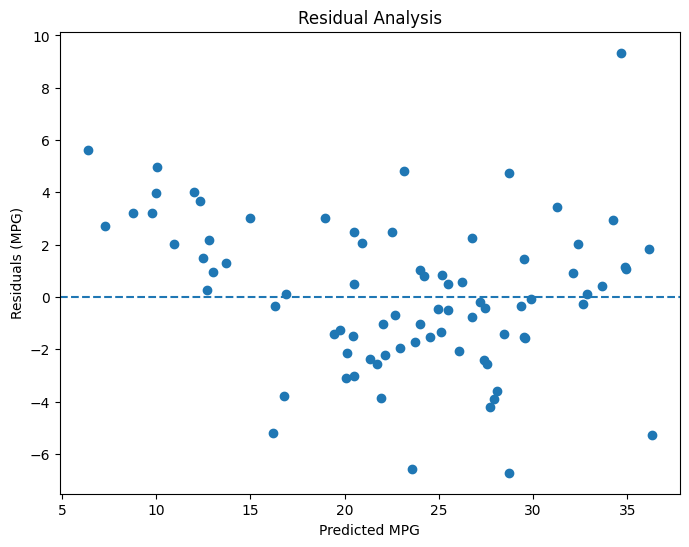

In [33]:
# STEP 8: Calculate prediction residuals

residuals = y_test - y_pred

plt.figure(figsize=(8, 6))

plt.scatter(y_pred, residuals)

plt.axhline(y=0, linestyle='--')

plt.title("Residual Analysis")

plt.xlabel("Predicted MPG")
plt.ylabel("Residuals (MPG)")

plt.show()

In [34]:
# STEP 9: Import preprocessing tools

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Preprocessing tools imported successfully!")

Preprocessing tools imported successfully!


In [35]:
# STEP 10: Prepare original dataset for improved modelling

X = df.drop(columns=['mpg'])
y = df['mpg']

# Treat origin as a categorical variable
X['origin'] = X['origin'].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 318
Testing records: 80


In [36]:
# STEP 11: Create preprocessing pipeline

numeric_features = [
    'cylinders',
    'displacement',
    'horsepower',
    'weight',
    'acceleration',
    'model_year'
]

categorical_features = ['origin']

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_features),
    ('categorical', categorical_pipeline, categorical_features)
])

model_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('regression', LinearRegression())
])

model_pipeline.fit(X_train, y_train)

print("Improved model trained successfully!")

Improved model trained successfully!


In [37]:
# STEP 12: Evaluate improved model

improved_predictions = model_pipeline.predict(X_test)

mae = mean_absolute_error(y_test, improved_predictions)

mse = mean_squared_error(y_test, improved_predictions)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, improved_predictions)

print("Improved Model Performance")
print("---------------------------")
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 3))

Improved Model Performance
---------------------------
MAE: 2.29
MSE: 8.34
RMSE: 2.89
R2 Score: 0.845
